# D2 Medellín — Grafo vial dirigido

Mismo esquema que `D2_grafo_bogota.ipynb`: congela crudos con sha256, construye segmentos y nodos, **no calcula pendiente** (eso lo hace el módulo de terreno) y exporta el paquete para la unión en D3.

**Fuentes (todas congeladas en la celda 2):**

| Qué | Enlace |
|---|---|
| Red vial — capa «Sentido vial» (REST, EPSG:9377) | https://www.medellin.gov.co/servidormapas/rest/services/mapas_nacionales/VC_Transporte/MapServer/3 |
| Ficha de metadatos de Sentido vial | https://www.medellin.gov.co/giscatalogacion/srv/api/records/b571f498-75c4-4554-b278-cf72c05498a2 |
| Dato abierto en GeoMedellín | https://www.medellin.gov.co/geomedellin/datosAbiertos/252 |
| MDT LiDAR 2021, 1 m (ficha) | https://www.medellin.gov.co/giscatalogacion/srv/api/records/440571dd-7f89-40aa-bcf9-0b99b311ca1d |
| MDT — descarga (Banco de Imágenes, requiere cuenta) | https://www.medellin.gov.co/mapgis9/mapa.jsp?aplicacion=49 |
| MDT — servicio de imagen «2024» (sin ficha propia) | https://www.medellin.gov.co/servidormapas/rest/services/ServiciosImagen/Modelo_digital_de_elevacion_medellin_2024/ImageServer |
| Licencia «Abierta» del Banco de Imágenes | https://www.medellin.gov.co/servicios/metadatos_gis/BancoImagenes/Terminos/Abierta.pdf |

**Licencias:** Sentido vial declara CC BY-SA 4.0, pero se construyó sobre OpenStreetMap (ODbL). La ficha del MDT se contradice (etiqueta CC BY-SA, PDF sin uso comercial y share-alike, campo «Use limitation» restrictivo). Mientras C1 no lo resuelva: se publica código e instrucciones, no el grafo ni el ráster.

**Diferencias con Bogotá:**
- La capa ya trae `oneway` (FT/TF/DW/N).
- Trae `f_elev`/`t_elev`: el nodo incluye el nivel, así un puente no se conecta con la calle de abajo.
- La fuente no tiene «dangles» por especificación, así que. Los nodos se forman por coordenada redondeada a cm y luego se fusionan los que distan menos de `TOL_FUSION_M` dentro del mismo nivel, sin unir nunca los dos extremos de una misma arista (celda 7b). La tolerancia se justifica con la sensibilidad de la celda 7c.. Los casi-cortes a menos de `TOLERANCIA_NODO_M` se reportan como diagnóstico, pero no se fusionan.

In [1]:
# Celda 1 — Rutas, imports y constantes
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

RAIZ_D = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "constantes_d1.py").exists())
sys.path.insert(0, str(RAIZ_D))
import constantes_d1 as cd
import d2_medellin as d2m

CARPETA_CRUDO = RAIZ_D / "datos_crudos" / "medellin" / f"{cd.PREFIJO_CRUDO_SVIAL_MED}_{cd.FECHA_CORTE_SVIAL_MED}"
CARPETA_META  = RAIZ_D / "datos_crudos" / "medellin" / "metadatos"
SALIDA        = RAIZ_D / "entregables" / "D2_medellin"
SALIDA.mkdir(parents=True, exist_ok=True)

print("Raíz Bloque D :", RAIZ_D)
print("Crudo         :", CARPETA_CRUDO)
print("Salida        :", SALIDA)
print("Corte         :", cd.FECHA_CORTE_SVIAL_MED, "| tolerancia nodo:", cd.TOLERANCIA_NODO_M, "m")

Raíz Bloque D : f:\Tesis\Grafo Bogotá
Crudo         : f:\Tesis\Grafo Bogotá\datos_crudos\medellin\sentido_vial_med_2026-09-21
Salida        : f:\Tesis\Grafo Bogotá\entregables\D2_medellin
Corte         : 2026-09-21 | tolerancia nodo: 2.0 m


In [2]:
# Celda 2 — Congelar metadatos y licencias (si ya existen, solo se re-hashean)
registro_meta = {}
for nombre, url in cd.URLS_METADATOS_MED.items():
    registro_meta[nombre] = d2m.congelar_get(url, CARPETA_META / nombre)
tabla_meta = pd.DataFrame(registro_meta).T[["archivo", "sha256", "bytes", "descargado_ahora"]]
print(tabla_meta.to_string())

capa_json = json.loads((CARPETA_META / "sentido_vial_capa.json").read_text(encoding="utf-8"))
DOM_JERARQUIA = d2m.dominio(capa_json, "jerarquia_op")
DOM_ONEWAY    = d2m.dominio(capa_json, "oneway")
print("\nDominio oneway   :", DOM_ONEWAY)
print("Dominio jerarquía:", DOM_JERARQUIA)

                                                                 archivo                                                            sha256   bytes descargado_ahora
sentido_vial_capa.json                            sentido_vial_capa.json  d285929e53ff4ccef096051a6d43546028aae7be76e6366af7e6532c961e43f0   15317            False
sentido_vial_ficha.xml                            sentido_vial_ficha.xml  2e19f83ed37bf2a51109fa106ae5dac3ce06eb42af25f2f30a30aa31d237b213   36384            False
mdt_2021_ficha.xml                                    mdt_2021_ficha.xml  0c0b8338ff796b0749a1cf1f602089a93c7a457d94cd998a497266c9628d7762   65833            False
mdt_servicio_2024.json                            mdt_servicio_2024.json  918eeccc2a41995fa2315289d0718ba83d7023eecfac3526409b178efd12acd6    3666            False
licencia_banco_imagenes_abierta.pdf  licencia_banco_imagenes_abierta.pdf  cf34ee70b6b0037620e06c1fbd3c25ece1b22199bd58be408b218489e82fbcff  269286            False

Dominio oneway 

In [3]:
# Celda 3 — Descarga congelada de Sentido vial (sin red si el manifiesto existe)
manifiesto = d2m.descargar_sentido_vial_congelado(cd.URL_SENTIDO_VIAL_MED, CARPETA_CRUDO,
                                                  lote=cd.LOTE_SVIAL_MED)
print("Recién descargado :", manifiesto["recien_descargado"])
print("Fecha de descarga :", manifiesto["fecha_descarga"])
print("Objetos           :", manifiesto["n_objetos"], "en", len(manifiesto["paginas"]), "páginas")
print("Hash de conjunto  :", manifiesto["hash_conjunto"])
ids_congelados = json.loads((CARPETA_CRUDO / "ids_objetos.json").read_text())["objectIds"]

Recién descargado : False
Fecha de descarga : 2026-09-21T02:40:41-05:00
Objetos           : 35425 en 71 páginas
Hash de conjunto  : c9d53ebbdffe80e2de23167f82954e8015900c7d06fc5c308826ca043797358c


In [4]:
# Celda 4 — Lectura e inventario de la capa completa (todo el Valle de Aburrá)
ejes_todos = d2m.leer_ejes_congelados(CARPETA_CRUDO, manifiesto)
COL_OID = manifiesto["campo_oid"].lower()
print(len(ejes_todos), "ejes | columnas:", list(ejes_todos.columns))
print("\nGeometrías vacías:", int(ejes_todos.geometry.isna().sum()))
print("\noneway:\n", ejes_todos["oneway"].value_counts(dropna=False).to_string())
print("\nmunicipio:\n", ejes_todos["municipio"].value_counts(dropna=False).to_string())

fechas = pd.to_datetime(ejes_todos["fecha_act"], unit="ms", errors="coerce")
print("\nfecha_act — mín:", fechas.min(), "| máx:", fechas.max(), "| nulas:", int(fechas.isna().sum()))

35425 ejes | columnas: ['objectid', 'id_svial', 'nombre', 'jerarquia_op', 'oneway', 'nro_carriles', 'paso_nivel', 'f_elev', 't_elev', 'actualizado', 'fecha_act', 'observ', 'municipio', 'st_length(shape)', 'geometry']

Geometrías vacías: 1

oneway:
 oneway
DW     25065
FT      9119
TF       882
N        327
NaN       31
0          1

municipio:
 municipio
Medellin                     24198
Bello                         3755
Itagui                        2084
Envigado                      2037
Caldas                         606
Copacabana                     574
Sabaneta                       504
La Estrella                    453
Medellín                       303
Resto                          271
NaN                            265
Girardota                      216
Barbosa                        135
Corregimiento Santa Elena       15
medellín                         2
Medllin                          2
Medelin                          2
mEDELLÍN                         1
Medelín      

In [5]:
# Celda 5 — Límite oficial IGAC de Medellín (código DANE 05001), el mismo de A2
RAIZ_TESIS = next(p for p in [RAIZ_D, *RAIZ_D.parents] if (p / "Bloque A" / "constantes.py").exists())
sys.path.insert(0, str(RAIZ_TESIS / "Bloque A"))
import constantes as cA

CFG_LIM = cA.AREAS_ESTUDIO["Medellin"]["limite"]
limite, ficha_limite = cA.cargar_limite_ciudad(
    archivo=CFG_LIM["archivo"],
    capa=CFG_LIM["capa"],
    nombre_ciudad="Medellín",
    procedencia=CFG_LIM["procedencia"],
    columna_codigo=CFG_LIM["columna_codigo"],
    codigo=CFG_LIM["codigos_dane"]["Medellin"],
)

limite = limite.to_crs(d2m.EPSG)
area_km2 = limite.geometry.area.sum() / 1e6
print("Registros:", len(limite), "| área:", round(area_km2, 1), "km²")
print("Procedencia:", json.dumps(ficha_limite, ensure_ascii=False, default=str, indent=2)[:600])
# Verificación independiente: Medellín tiene 380,6 km². Si el filtro toma otro
# municipio o se traga la capa nacional entera, la cifra se dispara y esto para.
assert len(limite) == 1 and 360 < area_km2 < 400, "El límite no parece ser solo Medellín."

Registros: 1 | área: 373.4 km²
Procedencia: {
  "ciudad": "Medellín",
  "archivo": "F:\\Tesis\\Bloque A\\Municipios_Junio_2026.gpkg",
  "capa": "Munpio",
  "crs_original": "EPSG:9377",
  "registros_en_la_capa": 1105,
  "columna_codigo": "MpCodigo",
  "codigo_filtrado": "05001",
  "geometrias_originales": 1,
  "entidad": "IGAC — Instituto Geográfico Agustín Codazzi",
  "url": "https://www.colombiaenmapas.gov.co/",
  "fecha_descarga_limite": "09/09/2026",
  "obtencion": "Descarga manual desde el portal Colombia en Mapas. Capa nacional de municipios, versión junio de 2026, 1.105 registros."
}


In [6]:
# Celda 6 — Recorte por el límite IGAC (vinculante). El atributo `municipio` queda como diagnóstico.
ejes_todos["municipio_norm"] = ejes_todos["municipio"].map(d2m.normalizar)
geo_limite = limite.geometry.union_all()

ejes_validos = ejes_todos[ejes_todos.geometry.notna() & ~ejes_todos.geometry.is_empty].copy()
ejes_validos["dentro_m"] = ejes_validos.geometry.intersection(geo_limite).length
ejes_validos["frac_dentro"] = ejes_validos["dentro_m"] / ejes_validos.geometry.length

# Regla: el eje entra si más de la mitad de su longitud cae dentro del límite.
# No se corta la geometría: partir un eje en el borde rompería la topología del grafo.
ejes_med = ejes_validos[ejes_validos["frac_dentro"] > 0.5].copy()

# Diagnóstico: qué tanto coincide el atributo con el criterio espacial.
attr_med = ejes_validos["municipio_norm"] == "MEDELLIN"
print(f"Ejes dentro del límite (criterio)     : {len(ejes_med):,}")
print(f"Ejes con atributo MEDELLIN            : {int(attr_med.sum()):,}")
print(f"  dentro del límite pero otro atributo: {int((~attr_med & (ejes_validos['frac_dentro'] > 0.5)).sum()):,}")
print(f"  atributo MEDELLIN pero fuera        : {int((attr_med & (ejes_validos['frac_dentro'] <= 0.5)).sum()):,}")
print("\nAtributos de los ejes que el límite acepta:\n",
      ejes_med["municipio_norm"].value_counts().to_string())
print(f"\nEjes de borde (entre 5% y 95% adentro): "
      f"{int(ejes_med['frac_dentro'].between(0.05, 0.95).sum()):,}")

if ejes_med["id_svial"].notna().all() and ejes_med["id_svial"].is_unique:
    COL_ID = "id_svial"
    ejes_med["id_svial"] = ejes_med["id_svial"].astype("int64")
else:
    COL_ID = COL_OID
    print("⚠ id_svial no sirve como ID -> se usa", COL_OID)
print("\nID de segmento basado en:", COL_ID)
print("Longitud física:", round(ejes_med.geometry.length.sum() / 1000, 1), "km")

Ejes dentro del límite (criterio)     : 24,578
Ejes con atributo MEDELLIN            : 24,503
  dentro del límite pero otro atributo: 261
  atributo MEDELLIN pero fuera        : 186

Atributos de los ejes que el límite acepta:
 municipio_norm
MEDELLIN                     24317
                               229
CORREGIMIENTO SANTA ELENA       15
BELLO                            5
ITAGUI                           4
MEDELIN                          3
MEDLLIN                          2
ENVIGADO                         1
MEDELLIH                         1
BARBOSA                          1

Ejes de borde (entre 5% y 95% adentro): 52

ID de segmento basado en: id_svial
Longitud física: 2312.6 km


In [7]:
# Celda 6b — Exclusión de tramos que OpenStreetMap identifica como no aptos para carros
# La lista la genera la celda 15 de medellin_prueba_osm.ipynb. Aquí solo se lee y se verifica.
ruta_excl = Path(cd.RUTA_EXCLUSION_OSM_MED)
ruta_man_excl = ruta_excl.with_name("D2M_exclusion_no_vehicular_osm_manifiesto.json")
sha_excl = d2m.sha256_archivo(ruta_excl)
man_excl = json.loads(ruta_man_excl.read_text(encoding="utf-8"))
assert sha_excl == cd.SHA256_EXCLUSION_OSM_MED == man_excl["sha256_csv"], \
    "La lista de exclusión no coincide con la huella registrada en constantes_d1.py"
assert man_excl["hash_conjunto_alcaldia"] == manifiesto["hash_conjunto"], \
    "La lista se calculó sobre otra descarga de la capa de la Alcaldía"
assert COL_ID == "id_svial", "La exclusión se identifica por id_svial"

exclusion = pd.read_csv(ruta_excl, encoding="utf-8-sig")
ids_excl = frozenset(exclusion["id_svial"].astype("int64"))
assert len(ids_excl) == len(exclusion), "id_svial repetido en la lista de exclusión"
faltan = ids_excl - set(ejes_med[COL_ID])
assert not faltan, f"{len(faltan)} id_svial de la lista no están en ejes_med (¿otro recorte?)"

excluidos = ejes_med[ejes_med[COL_ID].isin(ids_excl)]
OIDS_EXCLUIDOS = frozenset(excluidos[COL_OID].astype(int))
N_EJES_ANTES_EXCLUSION = len(ejes_med)
KM_ANTES_EXCLUSION = ejes_med.geometry.length.sum() / 1000
ejes_med = ejes_med[~ejes_med[COL_ID].isin(ids_excl)].copy()

por_motivo = (exclusion.groupby("motivo")["largo_m"].agg(["size", "sum"])
              .rename(columns={"size": "tramos", "sum": "m"}).assign(km=lambda t: (t["m"] / 1000).round(2))
              .drop(columns="m"))
print(f"Lista verificada: {len(ids_excl):,} tramos (OSM {man_excl['osm_estado_del_mapa']}, sha256 {sha_excl[:12]}…)")
print(por_motivo.to_string())
print(f"\nEjes: {N_EJES_ANTES_EXCLUSION:,} -> {len(ejes_med):,}")
print(f"Km físicos: {KM_ANTES_EXCLUSION:,.1f} -> {ejes_med.geometry.length.sum()/1000:,.1f}")

Lista verificada: 873 tramos (OSM 2026-09-25T06:17:59Z, sha256 3cb1c8c8662c…)
            tramos     km
motivo                   
ciclorruta       2   0.02
escaleras      123   7.32
peatonal       681  42.31
sendero         67  10.34

Ejes: 24,578 -> 23,705
Km físicos: 2,312.6 -> 2,252.6


In [8]:
print(ejes_med["oneway"].value_counts(dropna=False).to_string())
print("\nDominio declarado:", DOM_ONEWAY)

cero = ejes_med[ejes_med["oneway"] == "0"]
print(f"\n'0': {len(cero):,} ejes, {cero.geometry.length.sum()/1000:,.1f} km "
      f"({cero.geometry.length.sum()/ejes_med.geometry.length.sum():.1%} de la red)")
print("\nJerarquía:\n", cero["jerarquia_op"].map(DOM_JERARQUIA).value_counts(dropna=False).to_string())
print("\nCarriles:\n", cero["nro_carriles"].value_counts(dropna=False).head().to_string())
print("\nEjemplos:\n", cero[["nombre", "jerarquia_op", "nro_carriles", "paso_nivel"]].head(15).to_string())

oneway
DW     15727
FT      6786
TF       864
N        300
NaN       27
0          1

Dominio declarado: {'FT': 'FT', 'TF': 'TF', 'DW': 'DW', 'N': 'N'}

'0': 1 ejes, 0.2 km (0.0% de la red)

Jerarquía:
 jerarquia_op
2-Arteria Principal    1

Carriles:
 nro_carriles
NaN    1

Ejemplos:
            nombre  jerarquia_op  nro_carriles  paso_nivel
7193  Carrera 36A           2.0           NaN         NaN


In [9]:
# Celda 7 — Grafo dirigido
aristas, nodos, multipartes = d2m.construir_aristas(ejes_med, COL_ID, prefijo="MED")
aristas["jerarquia"] = aristas["jerarquia_op"].map(DOM_JERARQUIA)
aristas["fecha_act"] = (pd.to_datetime(aristas["fecha_act"], unit="ms", errors="coerce")
                          .dt.strftime("%Y-%m-%d"))

print(f"Aristas dirigidas : {len(aristas):,}")
print(f"Nodos             : {len(nodos):,}")
print(f"Km dirigidos      : {aristas['longitud_m'].sum()/1000:,.1f}")
print(f"Excluidos por N   : {(ejes_med['oneway'] == 'N').sum():,} ejes")
print(f"Sentido asumido   : {int(aristas['sentido_asumido'].sum()):,} aristas (oneway nulo)")
print(f"Aristas elevadas  : {int(aristas['es_elevado'].sum()):,} (puente/paso a nivel)")
print(f"Ejes multiparte   : {len(multipartes)}")
if len(multipartes): print(multipartes.sort_values('n_partes', ascending=False).head(10).to_string())
print("\nPor jerarquía:\n", aristas.groupby("jerarquia", dropna=False)["longitud_m"].agg(["size", "sum"]).assign(km=lambda t: t["sum"]/1000).drop(columns="sum").to_string())

⚠ Valores de oneway no documentados {'0'}: 1 ejes, 0.01% de la red. Se tratan como sin dato (doble vía asumida).
Aristas dirigidas : 39,160
Nodos             : 16,472
Km dirigidos      : 3,752.3
Excluidos por N   : 300 ejes
Sentido asumido   : 56 aristas (oneway nulo)
Aristas elevadas  : 493 (puente/paso a nivel)
Ejes multiparte   : 0

Por jerarquía:
                                        size           km
jerarquia                                               
1-Autopista                             126    65.796165
2-Arteria Principal                    3335   445.506187
3-Arteria Menor                         801    81.171861
4-Colectora                            7792   623.144284
5-Servicio                            20824  1708.508828
6-Vía Rural (Cabecera corregimiento)    759    88.817053
7-Vía Rural (Vías inter-veredales)      781   401.460598
8-Privada                                 9     8.725134
99-No Clasificada                       184    18.007746
NaN                

In [10]:
# Celda 7b — Fusión de nodos separados por ruido de digitalización
TOL_FUSION_M = cd.TOLERANCIA_NODO_M

aristas, nodos, informe_fusion = d2m.fusionar_nodos_cercanos(
    aristas, nodos, TOL_FUSION_M, prefijo="MED")
print(json.dumps({k: v for k, v in informe_fusion.items() if k != "detalle_vetadas"},
                 indent=2, ensure_ascii=False))
if informe_fusion["vetadas_por_bucle"]:
    print("\nVetadas:", informe_fusion["detalle_vetadas"][:10])

{
  "tolerancia_m": 2.0,
  "pares_evaluados": 88,
  "fusiones": 76,
  "vetadas_por_bucle": 7,
  "nodos_antes": 16472,
  "nodos_despues": 16396,
  "desplazamiento_max_m": 1.995419755101307
}

Vetadas: [('MED_N014299', 'MED_N014301', 0.28635642153221724, 'crearía un bucle'), ('MED_N014299', 'MED_N014302', 0.5316013544747122, 'crearía un bucle'), ('MED_N010757', 'MED_N010758', 1.0331505216953842, 'crearía un bucle'), ('MED_N002982', 'MED_N002983', 1.421267040728697, 'crearía un bucle'), ('MED_N012520', 'MED_N012522', 1.4368368032536476, 'crearía un bucle'), ('MED_N008716', 'MED_N008719', 1.678868666982406, 'crearía un bucle'), ('MED_N003225', 'MED_N003228', 1.9461243535937183, 'crearía un bucle')]


In [11]:
# Celda 7c — Sensibilidad de la topología a la tolerancia de fusión
import networkx as nx
aristas0, nodos0, _ = d2m.construir_aristas(ejes_med, COL_ID, prefijo="MED")
filas = []
for tol in [0.0, 0.10, 0.25, 0.50, 1.00, 2.00]:
    if tol == 0:
        a, n, inf = aristas0, nodos0, {"fusiones": 0, "vetadas_por_bucle": 0}
    else:
        a, n, inf = d2m.fusionar_nodos_cercanos(aristas0, nodos0, tol, prefijo="MED")
    G_t = nx.DiGraph(); G_t.add_edges_from(zip(a["u"], a["v"]))
    comps_t = list(nx.strongly_connected_components(G_t))
    m = max(comps_t, key=len)
    filas.append({"tol_m": tol, "nodos": len(n), "fusiones": inf["fusiones"],
                  "vetadas": inf["vetadas_por_bucle"], "componentes": len(comps_t),
                  "frac_aristas_mayor": round(float((a["u"].isin(m) & a["v"].isin(m)).mean()), 4),
                  "bucles": int((a["u"] == a["v"]).sum())})
sensibilidad_fusion = pd.DataFrame(filas)
print(sensibilidad_fusion.to_string(index=False))
sensibilidad_fusion.to_csv(SALIDA / "D2M_sensibilidad_tolerancia_fusion.csv", index=False)

⚠ Valores de oneway no documentados {'0'}: 1 ejes, 0.01% de la red. Se tratan como sin dato (doble vía asumida).
 tol_m  nodos  fusiones  vetadas  componentes  frac_aristas_mayor  bucles
  0.00  16472         0        0          240              0.9879      10
  0.10  16448        24        0          224              0.9885      10
  0.25  16433        39        0          214              0.9888      10
  0.50  16424        48        1          199              0.9894      10
  1.00  16413        59        2          159              0.9907      10
  2.00  16396        76        7          151              0.9915      10


In [12]:
# Celda 7d — ¿Alguna fusión conectaría una autopista donde no debería?
from scipy.spatial import cKDTree
inc = pd.concat([aristas0[["u", "jerarquia_op"]].rename(columns={"u": "n"}),
                 aristas0[["v", "jerarquia_op"]].rename(columns={"v": "n"})])
jer_de = inc.groupby("n")["jerarquia_op"].apply(lambda s: set(s.dropna().astype(int)))
filas = []
for nivel, g in nodos0.groupby("nivel"):
    xy = g[["x", "y"]].to_numpy(); ids = g["node_id"].to_numpy()
    for i, j in cKDTree(xy).query_pairs(2.0):
        ja, jb = jer_de.get(ids[i], set()), jer_de.get(ids[j], set())
        filas.append({"nodo_a": ids[i], "nodo_b": ids[j],
                      "distancia_m": float(np.hypot(*(xy[i] - xy[j]))),
                      "jer_a": sorted(ja), "jer_b": sorted(jb),
                      "toca_autopista": 1 in (ja | jb)})
pares_2m = pd.DataFrame(filas)
print(pares_2m["toca_autopista"].value_counts().to_string())
print(pares_2m[pares_2m["toca_autopista"]].sort_values("distancia_m").to_string())
pares_2m.to_csv(SALIDA / "D2M_revision_fusiones_autopista.csv", index=False)

toca_autopista
False    88
Empty DataFrame
Columns: [nodo_a, nodo_b, distancia_m, jer_a, jer_b, toca_autopista]
Index: []


In [13]:
# Celda 8 — Diagnósticos: componente fuerte y casi-cortes (informativos, no son pruebas)
import networkx as nx
from scipy.spatial import cKDTree

G = nx.DiGraph()
G.add_edges_from(zip(aristas["u"], aristas["v"]))
comps = list(nx.strongly_connected_components(G))
mayor = max(comps, key=len)
en_mayor = aristas["u"].isin(mayor) & aristas["v"].isin(mayor)
aristas["en_componente_fuerte"] = en_mayor
print(f"Componentes fuertes: {len(comps):,}")
print(f"Mayor componente   : {en_mayor.mean():.1%} de aristas, {len(mayor)/len(nodos):.1%} de nodos")

casi = []
for nivel, grupo in nodos.groupby("nivel"):
    xy = grupo[["x", "y"]].to_numpy()
    for i, j in cKDTree(xy).query_pairs(cd.TOLERANCIA_NODO_M):
        casi.append((grupo["node_id"].iloc[i], grupo["node_id"].iloc[j], nivel,
                     float(np.hypot(*(xy[i] - xy[j])))))
casi = pd.DataFrame(casi, columns=["nodo_a", "nodo_b", "nivel", "distancia_m"])
print(f"Pares de nodos distintos a < {cd.TOLERANCIA_NODO_M} m (mismo nivel): {len(casi):,}")

solapados = nodos.groupby(["x", "y"])["nivel"].nunique()
print(f"Puntos con nodos en más de un nivel (cruces a desnivel): {int((solapados > 1).sum()):,}")
casi.to_csv(SALIDA / "D2M_diagnostico_casi_cortes.csv", index=False)

Componentes fuertes: 151
Mayor componente   : 99.1% de aristas, 98.5% de nodos
Pares de nodos distintos a < 2.0 m (mismo nivel): 6
Puntos con nodos en más de un nivel (cruces a desnivel): 2


In [14]:
# después de la celda 8
from shapely.geometry import Point
borde = geo_limite.boundary
nodos["dist_frontera_m"] = [borde.distance(Point(x, y)) for x, y in zip(nodos.x, nodos.y)]
nodos["es_frontera"] = (nodos["dist_frontera_m"] < 50) & (
    (nodos["grado_salida"] == 0) | (nodos["grado_entrada"] == 0))
print(f"Nodos ciegos sobre la frontera: {int(nodos['es_frontera'].sum()):,}")

Nodos ciegos sobre la frontera: 12


In [15]:
# Celda 8c — ¿Los casi-cortes son los que parten la red?
comp_de = {n: i for i, c in enumerate(comps) for n in c}
casi["mismo_componente"] = [
    comp_de.get(a) == comp_de.get(b) for a, b in zip(casi.nodo_a, casi.nodo_b)]
print(casi["mismo_componente"].value_counts().to_string())
print(casi[~casi["mismo_componente"]].sort_values("distancia_m").head(15).to_string())

mismo_componente
True    6
Empty DataFrame
Columns: [nodo_a, nodo_b, nivel, distancia_m, mismo_componente]
Index: []


In [16]:
# Celda 8d — Aristas cortas: dónde el error vertical del MDT domina la pendiente
SIGMA_Z_M = cd.SIGMA_Z_ADOPTADO_MED_M   # el de la rama oficial de Medellin
L = aristas["longitud_m"]
ANCHO_M = cd.RAMAS_PENDIENTE_MED[cd.RAMA_OFICIAL_MED]["ancho_correlacion_m"]
error_pct = lambda d: 100 * SIGMA_Z_M * np.sqrt(2 * (1 - np.exp(-d / ANCHO_M))) / d   # mismo modelo de D3
ruido_pct = error_pct(L)
print(f"Error de pendiente por longitud (σz = {SIGMA_Z_M:g} m, ancho de correlación {ANCHO_M:g} m):")
for umbral in [2, 5, 10, 20]:
    sel = L < umbral
    print(f"  aristas < {umbral:>2} m: {int(sel.sum()):>6,} ({sel.mean():.2%})"
          f" | error ≥ {error_pct(umbral):.1f} %")
print(f"\nAristas con ruido de pendiente > 5 %: {int((ruido_pct > 5).sum()):,}")

print("\nComposición de es_elevado (paso_nivel contra niveles de nodo):")
print(pd.crosstab(pd.to_numeric(aristas["paso_nivel"], errors="coerce").fillna(-1).astype(int)
                    .rename("paso_nivel (-1 = nulo)"),
                  ((aristas["nivel_u"] != 0) | (aristas["nivel_v"] != 0)).rename("nivel ≠ 0"),
                  margins=True).to_string())

Error de pendiente por longitud (σz = 0.539 m, ancho de correlación 59.2 m):
  aristas <  2 m:      8 (0.02%) | error ≥ 6.9 %
  aristas <  5 m:    170 (0.43%) | error ≥ 4.3 %
  aristas < 10 m:  1,047 (2.67%) | error ≥ 3.0 %
  aristas < 20 m:  3,256 (8.31%) | error ≥ 2.0 %

Aristas con ruido de pendiente > 5 %: 73

Composición de es_elevado (paso_nivel contra niveles de nodo):
nivel ≠ 0               False  True    All
paso_nivel (-1 = nulo)                    
-1                      36300     0  36300
0                        2357     0   2357
1                         492     0    492
2                          10     1     11
All                     39159     1  39160


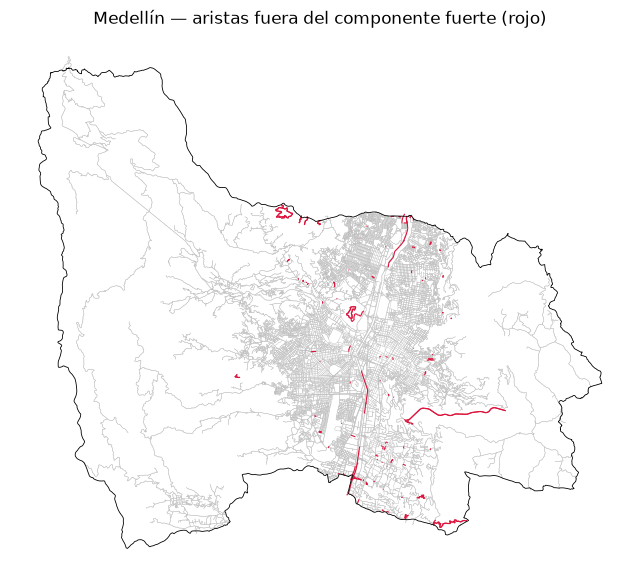

In [17]:
# Celda 9 — Exportación
import matplotlib.pyplot as plt

COLS = ["segmento_id", "id_eje", "parte", "n_partes", "sentido_arista", "oneway_fuente",
        "sentido_asumido", "u", "v", "nivel_u", "nivel_v", "es_elevado", "longitud_m",
        "jerarquia_op", "jerarquia", "nombre", "nro_carriles", "paso_nivel", "fecha_act",
        "en_componente_fuerte", "geometry"]
aristas = aristas[COLS]
RUTA_GPKG = SALIDA / "D2M_segmentos_para_pendiente.gpkg"
if RUTA_GPKG.exists(): RUTA_GPKG.unlink()
aristas.to_file(RUTA_GPKG, layer="segmentos", driver="GPKG")
aristas.drop(columns="geometry").assign(wkt=aristas.geometry.to_wkt()).to_csv(
    SALIDA / "D2M_segmentos_para_pendiente.csv", index=False)
nodos.to_csv(SALIDA / "nodos_medellin.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 9))
aristas[en_mayor.values].plot(ax=ax, color="0.75", linewidth=0.3)
aristas[~en_mayor.values].plot(ax=ax, color="crimson", linewidth=0.8)
limite.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.set_title("Medellín — aristas fuera del componente fuerte (rojo)"); ax.set_axis_off()
fig.savefig(SALIDA / "D2M_aristas_fuera_componente_fuerte.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
lim = limite.geometry.union_all()

fuera = ejes_med[~ejes_med.geometry.within(lim.buffer(1))].copy()
fuera["dentro_m"] = fuera.geometry.intersection(lim).length
fuera["fuera_m"]  = fuera.geometry.length - fuera["dentro_m"]
print(f"Ejes de Medellín que tocan el borde o salen: {len(fuera):,}")
print(f"  totalmente fuera : {(fuera['dentro_m'] < 1).sum():,}")
print(f"  parcialmente     : {(fuera['dentro_m'] >= 1).sum():,}")
print(fuera.nlargest(10, "fuera_m")[["nombre", "municipio", "dentro_m", "fuera_m"]].to_string())

otros = ejes_todos[~ejes_todos[COL_OID].isin(ejes_med[COL_OID])].copy()
otros["dentro_m"] = otros.geometry.intersection(lim).length
adentro = otros[otros["dentro_m"] > 1]
print(f"\nEjes de otros municipios que entran: {len(adentro):,}")
print(adentro.groupby("municipio")["dentro_m"].agg(["size", "sum"]).sort_values("sum", ascending=False).to_string())

Ejes de Medellín que tocan el borde o salen: 63
  totalmente fuera : 0
  parcialmente     : 63
                        nombre municipio     dentro_m      fuera_m
13146    Via vereda el retorno  Medellin  1969.259969  1014.337460
28154       Antigua via al mar  Medellin  4099.361639   664.797798
28573                      NaN  Medellin   464.839365   422.796746
33035  Via Vereda Barro Blanco  Medellin   454.402600   359.744335
32016                      NaN  Medellin   369.529895   328.303975
13143  AP Sur / Calz Izquierda  Medellin   439.289494   277.668842
8932         Camino de Jalisco  Medellin   591.090840   266.233225
34120               Carrera 15  Medellin   240.096464   157.303592
34191               Carrera 68  Medellin   251.621861   155.862311
13271            AP Norte >(N)  Medellin   349.809230   133.030172

Ejes de otros municipios que entran: 935
           size           sum
municipio                    
Medellin    893  62437.173838
Resto         5   5908.059250
Itagui

In [19]:
# Bucles
bucles = aristas[aristas["u"] == aristas["v"]]
print("BUCLES\n", bucles[["segmento_id", "id_eje", "nombre", "jerarquia",
                          "oneway_fuente", "longitud_m", "u"]].to_string())

# Duplicados
dup = aristas[aristas.duplicated(subset=["u", "v", "longitud_m"], keep=False)]
print("\nDUPLICADOS\n", dup.sort_values(["u", "v"])[
    ["segmento_id", "id_eje", "nombre", "jerarquia", "oneway_fuente",
     "longitud_m", "u", "v"]].to_string())

# ¿Los duplicados tienen la misma geometría o solo los mismos extremos?
for (u, v, L), g in dup.groupby(["u", "v", "longitud_m"]):
    geoms = list(g.geometry)
    iguales = all(geoms[0].equals(x) for x in geoms[1:])
    print(f"{u}->{v}  {len(g)} aristas, {L:.1f} m, geometría idéntica: {iguales}")

BUCLES
            segmento_id  id_eje nombre                             jerarquia oneway_fuente  longitud_m            u
1168   MED_111320_0_FT  111320    NaN                                   NaN            DW   65.182028  MED_N012234
1169   MED_111320_0_TF  111320    NaN                                   NaN            DW   65.182028  MED_N012234
4797   MED_113768_0_FT  113768    NaN                                   NaN            DW  176.202889  MED_N012498
4798   MED_113768_0_TF  113768    NaN                                   NaN            DW  176.202889  MED_N012498
24010  MED_126113_0_FT  126113    NaN                            5-Servicio            DW   63.362411  MED_N007096
24011  MED_126113_0_TF  126113    NaN                            5-Servicio            DW   63.362411  MED_N007096
25750  MED_127130_0_FT  127130    NaN  6-Vía Rural (Cabecera corregimiento)            DW  172.945914  MED_N000437
25751  MED_127130_0_TF  127130    NaN  6-Vía Rural (Cabecera corregimien

In [20]:
# Duplicados reales: geometría idéntica, id_eje distinto
from collections import defaultdict
por_geom = defaultdict(list)
for sid, ide, geom in zip(aristas.segmento_id, aristas.id_eje, aristas.geometry):
    por_geom[geom.wkb].append((sid, ide))

reales = {k: v for k, v in por_geom.items()
          if len({ide for _, ide in v}) > 1}
print(f"Geometrías compartidas por más de un id_eje: {len(reales)}")
for v in list(reales.values())[:20]:
    print(v)

Geometrías compartidas por más de un id_eje: 1
[('MED_138877_0_FT', 138877), ('MED_138903_0_FT', 138903)]


In [21]:
# Celda 10 — Pruebas de exportación
pruebas = d2m.pruebas_exportacion(
    ids_congelados=ids_congelados, ejes_todos=ejes_todos, ejes_med=ejes_med,
    aristas=aristas, nodos=nodos, limite=limite, col_oid=COL_OID,
    ruta_gpkg=RUTA_GPKG, capa_gpkg="segmentos", tol_nodo=TOL_FUSION_M,
    oids_excluidos=OIDS_EXCLUIDOS, ids_excluidos=ids_excl)
print(pruebas.to_string(index=False))
n_ok = (pruebas["resultado"] == "PASA").sum()
print(f"\n{n_ok} de {len(pruebas)} pruebas pasan")
assert n_ok == len(pruebas), "Hay pruebas que fallan: no exportar el paquete."
pruebas.to_csv(SALIDA / "D2M_pruebas_exportacion.csv", index=False)

prueba                                  nombre resultado                                                                               detalle
   T01              Completitud de la descarga      PASA                                   35425 filas, 35425 oid únicos, 35425 IDs congelados
   T02       CRS 9377 y extensión del servicio      PASA                                  EPSG 9377, bbox (4682775, 2215663, 4754194, 2283077)
   T03          Longitud vs campo del servidor      PASA                                    campo st_length(shape); dif. relativa máx 7.94e-06
   T04           Recorte por límite IGAC 05001      PASA mínimo 51.4% adentro entre los aceptados; 0 ejes omitidos con más de la mitad adentro
   T05    Balance de sentidos (2·DW + FT + TF)      PASA                                                    esperadas 39160, construidas 39160
   T06                Geometría corre de u a v      PASA         desfase máx 1.0023 m (tolerancia 2.0 m); 0 geometrías más cerca de v que de u

In [22]:
print(casi["distancia_m"].describe().to_string())
print("\nPor rango:")
import numpy as np
cortes = [0, 0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
print(pd.cut(casi["distancia_m"], cortes, include_lowest=True)
        .value_counts().sort_index().to_string())
print("\nSolo los que parten la red:")
print(pd.cut(casi.loc[~casi["mismo_componente"], "distancia_m"], cortes, include_lowest=True)
        .value_counts().sort_index().to_string())

count    6.000000
mean     1.320705
std      0.540144
min      0.407983
25%      1.130180
50%      1.429052
75%      1.618361
max      1.946124

Por rango:
distancia_m
(-0.001, 0.01]    0
(0.01, 0.05]      0
(0.05, 0.1]       0
(0.1, 0.25]       0
(0.25, 0.5]       1
(0.5, 1.0]        0
(1.0, 2.0]        5

Solo los que parten la red:
distancia_m
(-0.001, 0.01]    0
(0.01, 0.05]      0
(0.05, 0.1]       0
(0.1, 0.25]       0
(0.25, 0.5]       0
(0.5, 1.0]        0
(1.0, 2.0]        0


In [23]:
# Celda 11 — Huellas, contrato de intercambio y bitácora
huella = d2m.huella_segmentos(aristas)
archivos = ["D2M_segmentos_para_pendiente.csv", "nodos_medellin.csv",
            "D2M_pruebas_exportacion.csv", "D2M_diagnostico_casi_cortes.csv", "D2M_sensibilidad_tolerancia_fusion.csv",
            "D2M_revision_fusiones_autopista.csv"]
huellas = {
    "fecha_generacion": d2m.ahora_iso(),
    "hash_conjunto_crudo": manifiesto["hash_conjunto"],
    "huella_segmentos_gpkg": huella,
    "definicion_huella": ("sha256 sobre, para cada fila ordenada por segmento_id: "
                          "str(segmento_id) en UTF-8 + byte 0x00 + geometry.wkb (shapely, 2D, "
                          "little-endian) + byte 0x01. Funcion: d2_medellin.huella_segmentos"),
    "sha256_archivos": {a: d2m.sha256_archivo(SALIDA / a) for a in archivos},
    "metadatos_congelados": {k: v["sha256"] for k, v in registro_meta.items()},
    "fusion_nodos": {k: v for k, v in informe_fusion.items() if k != "detalle_vetadas"},
    "limite_igac": ficha_limite,
    "exclusion_no_vehicular_osm": {"archivo": str(ruta_excl), "sha256": sha_excl,
                                   "manifiesto": man_excl, "ejes_antes": N_EJES_ANTES_EXCLUSION,
                                   "km_fisicos_antes": round(KM_ANTES_EXCLUSION, 3)},
    "conteos": {"ejes_valle": len(ejes_todos), "ejes_medellin": len(ejes_med),
                "aristas": len(aristas), "nodos": len(nodos),
                "km_fisicos": round(ejes_med.geometry.length.sum() / 1000, 3),
                "km_dirigidos": round(aristas["longitud_m"].sum() / 1000, 3),
                "aristas_elevadas": int(aristas["es_elevado"].sum()),
                "aristas_sentido_asumido": int(aristas["sentido_asumido"].sum()),
                "componentes_fuertes": len(comps),
                "frac_aristas_componente_fuerte": round(float(en_mayor.mean()), 4),
                "aceptados_con_otro_atributo": int((~attr_med & (ejes_validos["frac_dentro"] > 0.5)).sum()),
                "atributo_medellin_excluidos": int((attr_med & (ejes_validos["frac_dentro"] <= 0.5)).sum()),
                "nodos_frontera_ciegos": int(nodos["es_frontera"].sum())},
}
(SALIDA / "D2M_huellas_salidas.json").write_text(json.dumps(huellas, ensure_ascii=False, indent=2), encoding="utf-8")

# Error de pendiente con el mismo modelo de D3: rho = exp(-L/ancho), error = sz*sqrt(2(1-rho))/L
_sz = cd.SIGMA_Z_ADOPTADO_MED_M
_anc = cd.RAMAS_PENDIENTE_MED[cd.RAMA_OFICIAL_MED]["ancho_correlacion_m"]
_err = lambda L: 100 * _sz * np.sqrt(2 * (1 - np.exp(-L / _anc))) / L
contrato = {
    "ciudad": "Medellín", "codigo_dane": "05001",
    "archivo": "D2M_segmentos_para_pendiente.gpkg", "capa": "segmentos",
    "n_segmentos": len(aristas), "huella_segmentos": huella,
    "crs": "EPSG:9377",
    "convencion_signo": "La geometría corre de u a v; pendiente positiva = sube en el sentido de la fila",
    "unidad_pendiente": "porcentaje",
    "columnas_retorno": list(cd.COLUMNAS_RETORNO_PENDIENTE_MED),
    "mdt_crs": cd.MDT_MED_CRS,
    "red_crs": "EPSG:9377",
    "sigma_z_m": cd.RAMAS_PENDIENTE_MED[cd.RAMA_OFICIAL_MED]["sigma_z_m"],
    "sigma_z_origen": cd.RAMAS_PENDIENTE_MED[cd.RAMA_OFICIAL_MED]["descripcion"],
    "ancho_correlacion_m": cd.RAMAS_PENDIENTE_MED[cd.RAMA_OFICIAL_MED]["ancho_correlacion_m"],
    "regla_tuneles": "es_tunel=True: pendiente de boca a boca; n_puntos_muestreados = 2; ganancia/pérdida = diferencia entre bocas; acumulada = |neta|; FT y TF marcados igual",
    "regla": "Una fila por segmento_id, sin agregar ni quitar filas; segmento_id se usa tal cual",
    "mdt_recomendado": {
        "producto": "DTM-LiDAR Medellín 2021, 1 m, EPSG:6257 (grilla urbana de Medellín; reproyectar cada punto antes de muestrear), alturas ortométricas, RMSEz 0,1 m (ficha)",
        "ficha": cd.URLS_METADATOS_MED_LEGIBLES["mdt_2021_ficha"],
        "servicio_programatico": cd.URL_MDT_MED_SERVICIO,
        "condicion": "Usar el servicio solo si la celda 12 demuestra que es el mismo ráster de 2021",
    },
    "advertencias": [
        "es_elevado=True: puente o túnel (paso_nivel = 1). En un puente el MDT da el suelo bajo el tablero; en un túnel, la montaña encima. La pendiente neta entre extremos puede servir, la acumulada no",
        "Túneles: el de Occidente (MED_132113, 4,7 km) está marcado es_elevado; varios tramos llamados 'Tunel de Oriente' (MED_138414 de 1,8 km, MED_138416 de 2,1 km) NO lo están: verificar en el mapa si son el túnel o la vía de acceso antes de usar su pendiente acumulada",
        "Tramos largos: 28 ejes miden más de 2 km (el mayor, MED_132178, 21 km de vía veredal sin cruces); su pendiente neta promedia subidas y bajadas: usar la acumulada",
        "sentido_asumido=True: oneway nulo o no documentado en la fuente, se asumió doble vía",
        f"Bucles (u == v): {int((aristas['u'] == aristas['v']).sum())} aristas; su pendiente neta es 0 por construcción aunque el tramo suba y baje",
        "Tramo duplicado en la fuente: MED_138877_0_FT y MED_138903_0_FT tienen geometría idéntica; recibirán la misma pendiente",
        "El límite de pendiente_extrema (35 %) se fijó con Bogotá; en Medellín puede haber tramos reales por encima: revisar antes de marcarlos como error",
        f"Error vertical: σz = {cd.SIGMA_Z_ADOPTADO_MED_M:g} m (rama {cd.RAMA_OFICIAL_MED}) y ancho de correlación {cd.RAMAS_PENDIENTE_MED[cd.RAMA_OFICIAL_MED]['ancho_correlacion_m']:g} m; túneles: pendiente de boca a boca con 2 puntos y columna es_tunel",
        f"Aristas cortas: con σz = {_sz:g} m y ancho de correlación {_anc:g} m (ρ = exp(−L/ancho), error = σz·√(2(1−ρ))/L, el mismo modelo de D3) el error de la pendiente es ≈ {_err(1):.1f} % en 1 m, {_err(5):.1f} % en 5 m y {_err(20):.1f} % en 20 m; ver celda 8d antes de aplicar pendiente_extrema",
        f"paso_nivel = 2 en {int((pd.to_numeric(aristas['paso_nivel'], errors='coerce') == 2).sum())} aristas, con significado no documentado en la fuente (dominio vacío): revisar aparte antes de interpretar su pendiente",
        f"Se excluyeron {len(ids_excl):,} tramos de la Alcaldía que OpenStreetMap identifica como escaleras, peatonales o senderos (ver huellas)",
    ],
}
(SALIDA / "D2M_contrato_intercambio.json").write_text(json.dumps(contrato, ensure_ascii=False, indent=2), encoding="utf-8")
huellas["sha256_archivos"]["D2M_contrato_intercambio.json"] = d2m.sha256_archivo(SALIDA / "D2M_contrato_intercambio.json")
(SALIDA / "D2M_huellas_salidas.json").write_text(json.dumps(huellas, ensure_ascii=False, indent=2), encoding="utf-8")

bitacora = f"""# Bitácora D2 Medellín

## Procedencia
- Fuente vial: Sentido vial, Secretaría de Movilidad de Medellín ({cd.URL_SENTIDO_VIAL_MED})
- Descarga: {manifiesto['fecha_descarga']} | corte declarado {cd.FECHA_CORTE_SVIAL_MED}
- Hash de conjunto del crudo: {manifiesto['hash_conjunto']} (idéntico en todas las descargas realizadas entre el 20 y el 21 de septiembre)
- Huella de segmentos: {huella}
- Límite: IGAC, capa nacional de municipios (descarga manual, ver huellas)
- Paso manual declarado: la descarga del GeoTIFF del MDT exige cuenta en medellin.gov.co

## Resultado
- {len(ejes_med):,} ejes de Medellín -> {len(aristas):,} aristas dirigidas, {len(nodos):,} nodos
- Componente fuerte: {en_mayor.mean():.1%} de las aristas ({len(comps):,} componentes)
- Pruebas: {n_ok} de {len(pruebas)} pasan

## Decisiones
- Recorte por el límite IGAC (vinculante), no por el atributo `municipio`: un eje entra si más de la mitad de su longitud cae dentro.
- Fusión de nodos a {TOL_FUSION_M} m, igual que Bogotá: {informe_fusion['fusiones']} fusiones, {informe_fusion['vetadas_por_bucle']} vetadas por unir extremos de una misma arista; de {int(sensibilidad_fusion.loc[sensibilidad_fusion['tol_m'] == 0, 'componentes'].iloc[0])} a {len(comps)} componentes, sin bucles nuevos. Ninguna fusión involucra autopistas.
- Valores de `oneway` nulos o fuera del dominio: doble vía asumida y marcada ({int(aristas['sentido_asumido'].sum())} aristas).
- Bucles y tramo duplicado de la fuente: se conservan y se reportan.
- Red combinada: la red y los sentidos vienen de la Secretaría de Movilidad; se excluyeron {len(ids_excl):,} tramos ({KM_ANTES_EXCLUSION - ejes_med.geometry.length.sum()/1000:,.1f} km) que OpenStreetMap identifica como no aptos para carros ({', '.join(f'{k}: {v}' for k, v in man_excl['por_motivo'].items())}). Estado del mapa OSM: {man_excl['osm_estado_del_mapa']}.

## Hallazgos sobre la fuente
- `municipio` inutilizable como criterio: seis grafías erróneas, corregimientos con etiqueta propia; {int((~attr_med & (ejes_validos['frac_dentro'] > 0.5)).sum())} ejes dentro del límite con otra etiqueta y {int((attr_med & (ejes_validos['frac_dentro'] <= 0.5)).sum())} etiquetados Medellín fuera de él.
- `fecha_act` vacío en {int(pd.to_datetime(ejes_todos['fecha_act'], unit='ms', errors='coerce').isna().sum()):,} de {len(ejes_todos):,} registros: no permite analizar vigencia.
- `jerarquia_op` nula en {int(aristas['jerarquia'].isna().sum()):,} aristas ({aristas.loc[aristas['jerarquia'].isna(), 'longitud_m'].sum()/1000:,.0f} km).
- Un eje con `oneway = '0'`, fuera del dominio declarado.
- Tramo Calle 49 (47,5 m) cargado dos veces bajo `id_svial` 138877 y 138903.
- Huecos de digitalización de 1 cm a 2 m entre extremos de calle, que partían la red en {int(sensibilidad_fusion.loc[sensibilidad_fusion['tol_m'] == 0, 'componentes'].iloc[0])} componentes.
- La capa incluye como calles para carros tramos que OpenStreetMap registra como escaleras, peatonales o senderos ({len(ids_excl):,} excluidos).

## Limitaciones de la red combinada
- Los sentidos de circulación vienen de la Alcaldía y no se validaron en campo; con OSM hay un 5 % de desacuerdo de sentido sin resolver.
- No se modelan restricciones de giro (OSM las tiene; no se integraron).
- La exclusión de tramos no vehiculares depende de lo que registra OSM.

## Pendientes
- Licencia (C1): contradicción en la ficha del MDT; Sentido vial CC BY-SA 4.0 derivado de OSM (ODbL).
- Identidad del servicio de elevación «2024» con el LiDAR 2021 (celda 12), a cargo de quien descargue el MDT.
- Alcance urbano o municipal para la comparación con Bogotá en la fase 6.
"""
(SALIDA / "D2M_bitacora.md").write_text(bitacora, encoding="utf-8")
print(bitacora)

# Bitácora D2 Medellín

## Procedencia
- Fuente vial: Sentido vial, Secretaría de Movilidad de Medellín (https://www.medellin.gov.co/servidormapas/rest/services/mapas_nacionales/VC_Transporte/MapServer/3)
- Descarga: 2026-09-21T02:40:41-05:00 | corte declarado 2026-09-21
- Hash de conjunto del crudo: c9d53ebbdffe80e2de23167f82954e8015900c7d06fc5c308826ca043797358c (idéntico en todas las descargas realizadas entre el 20 y el 21 de septiembre)
- Huella de segmentos: 5baf0bc9b8d2ac59a29b21eafe4d36cd8c2803ce5e966d095fd2ca6db587a590
- Límite: IGAC, capa nacional de municipios (descarga manual, ver huellas)
- Paso manual declarado: la descarga del GeoTIFF del MDT exige cuenta en medellin.gov.co

## Resultado
- 23,705 ejes de Medellín -> 39,160 aristas dirigidas, 16,396 nodos
- Componente fuerte: 99.1% de las aristas (151 componentes)
- Pruebas: 15 de 15 pasan

## Decisiones
- Recorte por el límite IGAC (vinculante), no por el atributo `municipio`: un eje entra si más de la mitad de su longit

In [24]:
# Celda 12 — OPCIONAL: ¿el servicio «2024» es el mismo MDT LiDAR 2021?
# Requiere el GeoTIFF oficial descargado a mano del Banco de Imágenes y rasterio.
RUTA_TIF_2021 = None   # ej.: RAIZ_D / "datos_crudos" / "medellin" / "mdt" / "DTM_2021.tif"

if RUTA_TIF_2021 is not None:
    import rasterio, requests
    rng = np.random.default_rng(20260919)
    muestra = aristas.sample(n=300, random_state=20260919)
    pts = np.array([g.interpolate(0.5, normalized=True).coords[0] for g in muestra.geometry])
    from pyproj import Transformer
    with rasterio.open(RUTA_TIF_2021) as src:
        assert src.crs.to_epsg() == int(cd.MDT_MED_CRS.split(":")[1]), f"CRS del TIF: {src.crs}"
        _tr = Transformer.from_crs(f"EPSG:{d2m.EPSG}", src.crs, always_xy=True)
        _x, _y = _tr.transform(pts[:, 0], pts[:, 1])
        z_tif = np.array([v[0] for v in src.sample(zip(_x, _y))], dtype=float)
    z_srv = []
    for k in range(0, len(pts), 100):
        bloque = pts[k:k + 100]
        r = requests.post(cd.URL_MDT_MED_SERVICIO + "/getSamples", data={
            "geometry": json.dumps({"points": bloque.tolist(), "spatialReference": {"wkid": d2m.EPSG}}),
            "geometryType": "esriGeometryMultipoint", "returnFirstValueOnly": "true", "f": "json"}, timeout=120)
        r.raise_for_status(); d = r.json(); assert "error" not in d, d
        z_srv += [float(s["value"]) for s in sorted(d["samples"], key=lambda s: s["locationId"])]
    dif = np.abs(z_tif - np.array(z_srv))
    res = pd.DataFrame({"x": pts[:, 0], "y": pts[:, 1], "z_tif": z_tif, "z_servicio": z_srv, "dif_m": dif})
    res.to_csv(SALIDA / "D2M_identidad_mdt_servicio_vs_2021.csv", index=False)
    print("sha256 del GeoTIFF:", d2m.sha256_archivo(RUTA_TIF_2021))
    print(f"Diferencia |z| — mediana {np.median(dif):.3f} m, p95 {np.percentile(dif, 95):.3f} m, máx {dif.max():.3f} m")
    print("MISMO RÁSTER" if np.percentile(dif, 95) < 0.01 else "NO son el mismo ráster: no usar el servicio como sustituto")

In [25]:
restringidos = ejes_med[ejes_med["oneway"] == "N"].copy()
restringidos["jerarquia"] = restringidos["jerarquia_op"].map(DOM_JERARQUIA)

print(f"Tramos restringidos: {len(restringidos):,}")
print(f"Longitud total     : {restringidos.geometry.length.sum()/1000:,.1f} km "
      f"({restringidos.geometry.length.sum()/ejes_med.geometry.length.sum():.1%} de la red)")
print(f"Largo típico       : {restringidos.geometry.length.median():.0f} m\n")

print("Por tipo de vía:\n", restringidos["jerarquia"].value_counts(dropna=False).to_string())
print("\nNombres más frecuentes:\n", restringidos["nombre"].value_counts(dropna=False).head(20).to_string())
print("\nObservaciones de la fuente:\n", restringidos["observ"].value_counts(dropna=False).head(15).to_string())

Tramos restringidos: 300
Longitud total     : 20.2 km (0.9% de la red)
Largo típico       : 56 m

Por tipo de vía:
 jerarquia
NaN                                     192
5-Servicio                               88
4-Colectora                              10
99-No Clasificada                         5
6-Vía Rural (Cabecera corregimiento)      3
2-Arteria Principal                       2

Nombres más frecuentes:
 nombre
NaN                      40
Carrera 52 / Carabobo     8
Calle 51 / Boyacá         7
Calle 107                 7
Carrera 38                6
Calle 55                  5
Carrera 130               4
Calle 54                  4
Carrera 78D               4
Carrera 79                4
Calle 104                 4
Calle 112                 4
Calle 51                  4
Carrera 48                4
Carrera 80                4
Calle 108A                4
Calle 104B                4
Calle 51A                 3
Diagonal 64               3
Calle 116A                3

Observaciones de

## Conclusiones


- **Red:** capa «Sentido vial» de la Secretaría de Movilidad (corte 2026-09-21), depurada con OpenStreetMap: se excluyeron 873 tramos (60,0 km) que OSM registra como peatonales, escaleras, senderos o ciclorruta.
- **Grafo:** 23.705 ejes → 39.160 aristas dirigidas y 16.396 nodos; 2.252,6 km físicos (3.752,3 km dirigidos). El 99,1 % de las aristas está en la componente fuertemente conexa (151 componentes).
- **Pruebas:** 15 de 15 pasan. Huella de segmentos `5baf0bc9…`, idéntica en todas las corridas.
- **Decisiones:** recorte por el límite IGAC; fusión de nodos a 2 m (76 fusiones, 7 vetadas); oneway nulo como doble vía asumida (56 aristas).
- **Contrato (actualizado 2026-10-19):** MDT DTM-LiDAR 2021 en EPSG:6257 (la red está en 9377); σz 0,1 m (ficha) y ancho 59,2 m; columna `es_tunel` con pendiente de boca a boca.
- **Celda 12:** no ejecutada (opcional; requiere el GeoTIFF descargado a mano).
- **Pendientes:** respuesta de la Alcaldía sobre la licencia del MDT (derecho de petición radicado el 2026-09-25); significado de `paso_nivel = 2` (11 aristas); revisión en Street View de las pendientes extremas (lista que genera D3M).